In [1]:
!pip install gymnasium[toy-text] matplotlib numpy

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

#creates the Taxi environment
env = gym.make("Taxi-v4", render_mode="ansi")

#rseset environment
state, info = env.reset()

#display environment information
print("Number of states:", env.observation_space.n)
print("Number of actions:", env.action_space.n)
print("Starting state:", state)
print(env.render())

Number of states: 500
Number of actions: 6
Starting state: 144
+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




In [3]:
alpha = 0.1
gamma = 0.9
epsilon = 1.0
epsilon_decay = 0.9995
epsilon_min = 0.01
episodes = 10000

#Q-table with all values starting at zero
q_table = np.zeros((env.observation_space.n,
                    env.action_space.n))

#store rewards
rewards = []

#training loop
for episode in range(episodes):
    state, info = env.reset()
    done = False
    total_reward = 0

    while not done:
        #choose action using epsilon-greedy policy
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(q_table[state]))

        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        #update Q-table
        if terminated:
            target = reward
        else:
            target = reward + gamma * np.max(q_table[next_state])

        q_table[state, action] += alpha * (
            target - q_table[state, action]
        )

        state = next_state
        total_reward += reward

    rewards.append(total_reward)

    #decreases exploration over time
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

print("Training complete!")
print("Average reward (last 100 episodes):",
      np.mean(rewards[-100:]))


Training complete!
Average reward (last 100 episodes): 7.94


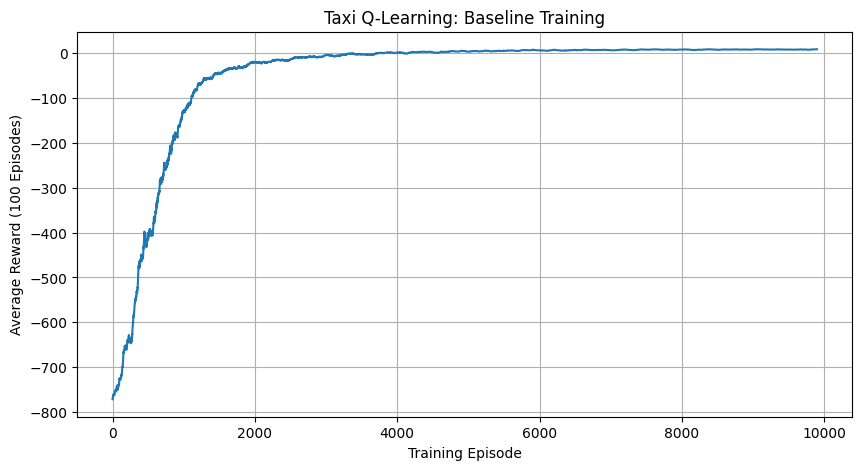

In [4]:
#calculate average reward every 100 episodes
window = 100
moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

#plots training rewards
plt.figure(figsize=(10, 5))
plt.plot(moving_average)

plt.title("Taxi Q-Learning: Baseline Training")
plt.xlabel("Training Episode")
plt.ylabel("Average Reward (100 Episodes)")
plt.grid(True)

plt.savefig("baseline_training.png")
plt.show()


Alpha 0.1: Average final reward = 6.46
Alpha 0.5: Average final reward = 7.25
Alpha 0.9: Average final reward = 7.60


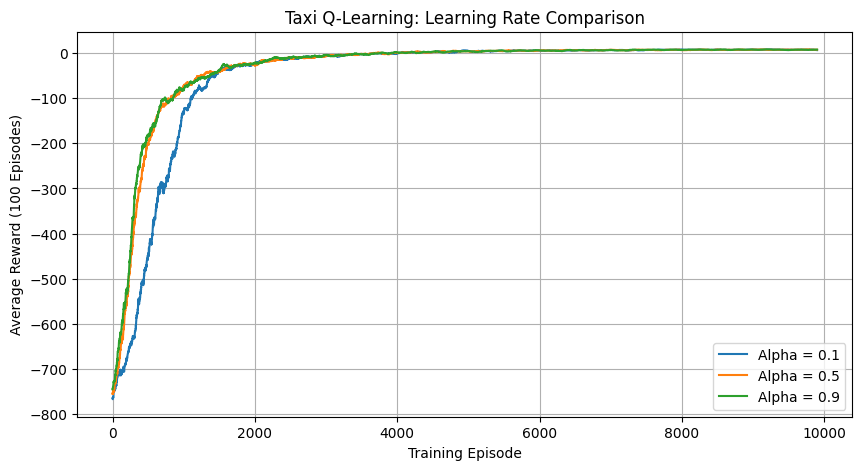

In [5]:
#function to train Taxi with different learning rates
def train_taxi(alpha, gamma=0.9, episodes=10000):
    q = np.zeros((env.observation_space.n,
                  env.action_space.n))

    epsilon = 1.0
    episode_rewards = []

    for episode in range(episodes):
        state, info = env.reset()
        done = False
        total_reward = 0

        while not done:
            if np.random.random() < epsilon:
                action = env.action_space.sample()
            else:
                action = int(np.argmax(q[state]))

            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            if terminated:
                target = reward
            else:
                target = reward + gamma * np.max(q[next_state])

            q[state, action] += alpha * (target - q[state, action])

            state = next_state
            total_reward += reward

        episode_rewards.append(total_reward)
        epsilon = max(0.01, epsilon * 0.9995)

    return episode_rewards, q


#compare the learning rates
learning_rates = [0.1, 0.5, 0.9]

plt.figure(figsize=(10, 5))

for rate in learning_rates:
    results, q = train_taxi(alpha=rate)

    moving_avg = np.convolve(
        results, np.ones(100) / 100, mode="valid"
    )

    plt.plot(moving_avg, label=f"Alpha = {rate}")

    print(f"Alpha {rate}: Average final reward = "
          f"{np.mean(results[-100:]):.2f}")

plt.title("Taxi Q-Learning: Learning Rate Comparison")
plt.xlabel("Training Episode")
plt.ylabel("Average Reward (100 Episodes)")
plt.legend()
plt.grid(True)
plt.savefig("learning_rate_comparison.png")
plt.show()


Gamma 0.5: Average final reward = 6.64
Gamma 0.9: Average final reward = 8.05
Gamma 0.99: Average final reward = 7.29


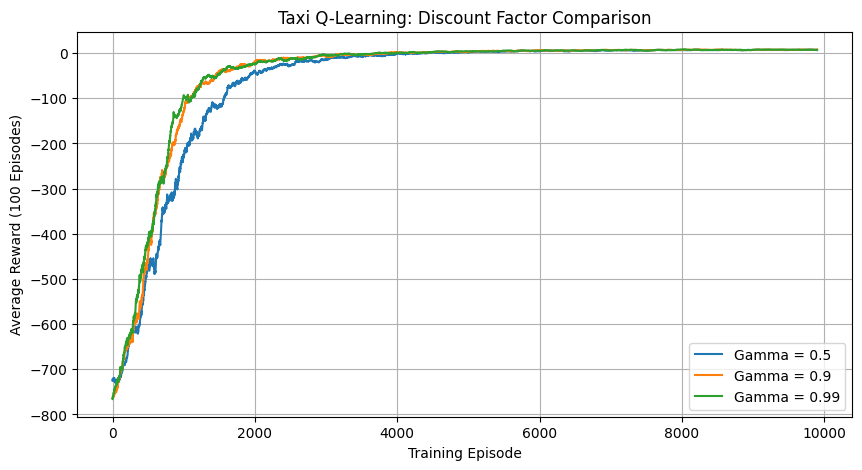

In [6]:
#compare discount factors
discount_factors = [0.5, 0.9, 0.99]

plt.figure(figsize=(10, 5))

for discount in discount_factors:
    results, q = train_taxi(
        alpha=0.1,
        gamma=discount,
        episodes=10000
    )

    moving_avg = np.convolve(
        results,
        np.ones(100) / 100,
        mode="valid"
    )

    plt.plot(moving_avg, label=f"Gamma = {discount}")

    print(f"Gamma {discount}: Average final reward = "
          f"{np.mean(results[-100:]):.2f}")

plt.title("Taxi Q-Learning: Discount Factor Comparison")
plt.xlabel("Training Episode")
plt.ylabel("Average Reward (100 Episodes)")
plt.legend()
plt.grid(True)

plt.savefig("discount_factor_comparison.png")
plt.show()


Decay 0.995: Average final reward = 7.03
Decay 0.999: Average final reward = 7.34
Decay 0.9995: Average final reward = 8.06


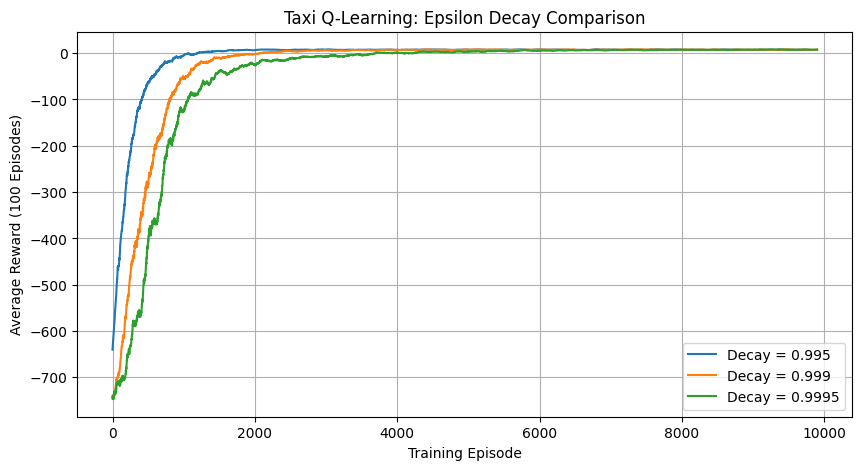

In [7]:
#compare epsilon decay rates
decay_rates = [0.995, 0.999, 0.9995]

plt.figure(figsize=(10, 5))

for decay in decay_rates:
    q = np.zeros((env.observation_space.n,
                  env.action_space.n))

    epsilon = 1.0
    episode_rewards = []

    for episode in range(10000):
        state, info = env.reset()
        done = False
        total_reward = 0

        while not done:
            if np.random.random() < epsilon:
                action = env.action_space.sample()
            else:
                action = int(np.argmax(q[state]))

            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            if terminated:
                target = reward
            else:
                target = reward + 0.9 * np.max(q[next_state])

            q[state, action] += 0.1 * (target - q[state, action])

            state = next_state
            total_reward += reward

        episode_rewards.append(total_reward)
        epsilon = max(0.01, epsilon * decay)

    moving_avg = np.convolve(
        episode_rewards,
        np.ones(100) / 100,
        mode="valid"
    )

    plt.plot(moving_avg, label=f"Decay = {decay}")

    print(f"Decay {decay}: Average final reward = "
          f"{np.mean(episode_rewards[-100:]):.2f}")

plt.title("Taxi Q-Learning: Epsilon Decay Comparison")
plt.xlabel("Training Episode")
plt.ylabel("Average Reward (100 Episodes)")
plt.legend()
plt.grid(True)

plt.savefig("epsilon_decay_comparison.png")
plt.show()


In [8]:
#trains the selected agent
best_alpha = 0.1
best_gamma = 0.99
best_decay = 0.999

best_q = np.zeros((env.observation_space.n,
                   env.action_space.n))

epsilon = 1.0

for episode in range(10000):
    state, info = env.reset()
    done = False

    while not done:
        if np.random.random() < epsilon:
            action = env.action_space.sample()
        else:
            action = int(np.argmax(best_q[state]))

        next_state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        if terminated:
            target = reward
        else:
            target = reward + best_gamma * np.max(best_q[next_state])

        best_q[state, action] += best_alpha * (
            target - best_q[state, action]
        )

        state = next_state

    epsilon = max(0.01, epsilon * best_decay)


#evaluates without exploration
test_rewards = []
test_steps = []
successes = 0

for episode in range(30):
    state, info = env.reset()
    done = False
    total_reward = 0
    steps = 0

    while not done:
        action = int(np.argmax(best_q[state]))

        state, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated

        total_reward += reward
        steps += 1

        if terminated:
            successes += 1

    test_rewards.append(total_reward)
    test_steps.append(steps)

print("Evaluation complete!")
print("Average reward:", np.mean(test_rewards))
print("Average steps:", np.mean(test_steps))
print("Success rate:", successes / 30 * 100, "%")


Evaluation complete!
Average reward: 7.566666666666666
Average steps: 13.433333333333334
Success rate: 100.0 %


In [9]:
#compares the baseline and best agent
for name, q in [("Baseline", q_table), ("Best", best_q)]:
    rewards = []
    steps_list = []
    successes = 0

    for episode in range(30):
        state, info = env.reset(seed=episode)
        done = False
        total_reward = 0
        steps = 0

        while not done:
            action = int(np.argmax(q[state]))
            state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            total_reward += reward
            steps += 1

            if terminated:
                successes += 1

        rewards.append(total_reward)
        steps_list.append(steps)

    print(name)
    print("Average reward:", np.mean(rewards))
    print("Average steps:", np.mean(steps_list))
    print("Success rate:", successes / 30 * 100, "%")
    print()


Baseline
Average reward: 7.633333333333334
Average steps: 13.366666666666667
Success rate: 100.0 %

Best
Average reward: 7.633333333333334
Average steps: 13.366666666666667
Success rate: 100.0 %



In [10]:
import imageio.v2 as imageio

#creates environment for recording
video_env = gym.make("Taxi-v4", render_mode="rgb_array")

frames = []
state, info = video_env.reset(seed=42)
done = False

#record the starting frame
frames.append(video_env.render())

while not done:
    action = int(np.argmax(best_q[state]))

    state, reward, terminated, truncated, info = video_env.step(action)
    done = terminated or truncated

    frames.append(video_env.render())

video_env.close()

#saves video
imageio.mimsave("taxi_trained_agent.mp4", frames, fps=3)

print("Video saved successfully!")
print("Number of frames:", len(frames))


Video saved successfully!
Number of frames: 14
